# Нейросетевой ранжировщик поверх гибридного пула

Ноутбук 02 показал, что линейная взвешенная сумма почти не использует запас общего пула кандидатов, а подобранные веса подходят пользователям с длинной историей и вредят пользователям с короткой. Здесь вместо взвешенной суммы кандидатов ранжирует небольшая нейросеть (MLP). На вход она получает те же колонки пула, что и линейный гибрид, и число книг пользователя в обучающей части. В линейной сумме число книг бесполезно: оно одинаково у всех кандидатов пользователя и не меняет их порядок. В нейросети оно может менять, каким сигналам доверять при короткой и длинной истории.

Генераторы, пул, признаки, сегменты и MMR те же, что в ноутбуке 02. Линейный гибрид пересчитывается той же процедурой (функция pipeline.tune_segment_weights), чтобы сравнение шло с тем же вариантом, что описан в отчёте.

## 1. Подготовка

В Colab ячейка ниже клонирует репозиторий и ставит scikit-surprise, при локальном запуске из папки notebooks её нужно пропустить. Для обучения достаточно процессора, GPU ускорит его, но не обязателен.

In [1]:
!git clone -q https://github.com/EgorCOStylev/goodbooks-hybrid-recsys.git
%cd goodbooks-hybrid-recsys
!pip install -q scikit-surprise

fatal: destination path 'goodbooks-hybrid-recsys' already exists and is not an empty directory.
/content/goodbooks-hybrid-recsys


In [2]:
import warnings
warnings.filterwarnings('ignore')

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

from recsys import data, hybrid, metrics, pipeline, ranker
from recsys.plots import show_table

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)

DATA_DIR    = Path(kagglehub.dataset_download('zygmunt/goodbooks-10k'))
SEED        = 42
THRESHOLD   = 4
K           = 10
N_PER_MODEL = 100
N_NEW       = 3000
LAMBDA      = 0.8
NEG_PER_POS = 20
EPOCHS      = 30
PATIENCE    = 3
SEGMENTS    = {'new': 'новые', 'active': 'активные'}

Using Colab cache for faster access to the 'goodbooks-10k' dataset.


## 2. Данные, разбиение и новые пользователи

Всё повторяет ноутбук 02: очистка как в домашнем задании, тест совпадает с тестом домашнего задания, валидация отрезается из обучающей части, 3000 пользователей валидации получают историю из 1–3 книг.

In [3]:
raw       = data.load_raw(DATA_DIR)
books     = raw['books']
ratings, _, _           = data.dedup_ratings(raw['ratings'])
books['original_title'] = books.original_title.fillna(books.title)
book_tags               = data.attach_tags(raw['book_tags'], books, raw['tags'])

fit, val, test = data.split_train_val_test(ratings, seed=SEED)
idx            = data.Index(users=np.sort(ratings.user_id.unique()), books=np.sort(books.id.unique()))
rel_val        = metrics.relevance_matrix(val, idx, THRESHOLD)
fit_t, _       = pipeline.simulate_new_users(fit, rel_val, idx, n_users=N_NEW, seed=SEED)
gr_count       = books.set_index('id').ratings_count.reindex(idx.books).to_numpy()

print(f'fit: {len(fit_t):,} оценок после обрезки, val: {len(val):,}, test: {len(test):,}')

fit: 593,700 оценок после обрезки, val: 136,860, test: 173,252


## 3. Пул валидации и линейный гибрид

Модели обучаются на обучающей части, пул строится для пользователей валидации. Веса линейного гибрида подбираются заново той же процедурой, что в ноутбуке 02, и должны совпасть с тепловой картой весов оттуда.

In [4]:
fitted    = pipeline.fit_models(fit_t, books, book_tags, idx)
val_users = np.flatnonzero(np.diff(rel_val.indptr))
pool_val  = pipeline.scored_pool(fitted, val_users, rel_val, n_per_model=N_PER_MODEL)
segment   = hybrid.segment_of(fitted.n_ratings)
weights   = pipeline.tune_segment_weights(pool_val, rel_val, segment, val_users, list(fitted.generators))

pd.DataFrame({f'{v}, {SEGMENTS[s]}': pd.Series(w) for (v, s), w in weights.items()}).fillna(0).round(2)

,"models, новые","features, новые","models, активные","features, активные"
bayes,0.00,0.10,0.00,0.00
bayes_mean,0.00,0.00,0.00,0.00
cf_explicit,0.10,0.10,0.05,0.05
cf_implicit,1.00,1.00,1.00,0.50
cf_max,0.00,0.00,0.00,2.00
cf_sum,0.00,0.25,0.00,0.00
content,0.05,0.05,0.05,0.05
content_cos,0.00,0.50,0.00,0.00
genre_affinity,0.00,0.00,0.00,0.00
known,0.25,0.25,0.00,0.00


## 4. Обучающая выборка ранжировщика

Ранжировщик обучается на пуле валидации, то есть на тех же данных, на которых подбирались веса линейного гибрида. 20% пользователей валидации отложены для ранней остановки: после каждой эпохи на них считается nDCG@10 по всем их кандидатам, и сохраняется лучшая эпоха. На остальных пользователях обучение идёт на всех релевантных кандидатах и 20 случайных нерелевантных на каждый релевантный. Без такой выборки на один релевантный кандидат в пуле приходились бы сотни нерелевантных.

Признаки: 6 рангов генераторов, 7 перцентилей признаков книги и пары (все от 0 до 1) и логарифм числа книг пользователя, деленный на логарифм 200 (максимум в датасете).

In [5]:
cols                 = list(fitted.generators) + list(pipeline.POOL_FEATURES)
train_users, es_users = ranker.split_users(val_users, share=0.2, seed=SEED)
rows                 = ranker.training_rows(pool_val, train_users, neg_per_pos=NEG_PER_POS, seed=SEED)
es_pool              = pool_val[pool_val.user.isin(es_users)].reset_index(drop=True)

print(f'Пользователей для обучения: {len(train_users):,}, для ранней остановки: {len(es_users):,}')
print(f'Обучающих строк: {len(rows):,}, из них релевантных: {pool_val.hit.values[rows].sum():,}')
print(f'Доля релевантных кандидатов во всём пуле валидации: {pool_val.hit.mean():.3%}')

Пользователей для обучения: 22,006, для ранней остановки: 5,501
Обучающих строк: 831,012, из них релевантных: 39,572
Доля релевантных кандидатов во всём пуле валидации: 0.382%


In [6]:
es_linear = hybrid.segment_score(es_pool, segment, {s: weights[('features', s)] for s in SEGMENTS})
es_cf     = hybrid.hybrid_score(es_pool, {'cf_implicit': 1.0})
print(f'nDCG@10 на пользователях ранней остановки: cf_implicit {hybrid.ranking_metrics(es_pool, es_cf, rel_val, K)["nDCG@10"]:.4f}, '
      f'линейный гибрид {hybrid.ranking_metrics(es_pool, es_linear, rel_val, K)["nDCG@10"]:.4f}')

nDCG@10 на пользователях ранней остановки: cf_implicit 0.1577, линейный гибрид 0.1611


## 5. Обучение

Сеть: два скрытых слоя по 64 и 32 нейрона с ReLU и dropout 0,1, на выходе одно число, скор кандидата. Лосс: бинарная кросс-энтропия по метке релевантности, оптимизатор Adam (шаг 0,001, L2 1e-5), батч 4096, не больше 30 эпох, остановка после трёх эпох без улучшения. В первом прогоне лимит был 10 эпох, и nDCG на пользователях ранней остановки у обеих сетей рос до последней эпохи, то есть обучение обрывал лимит. Лимит поднят по этой кривой, которая считается на валидации.

Обучаются две сети с одинаковыми настройками: с числом книг пользователя и без него. Разница между ними показывает, нужен ли сети этот признак, то есть подтверждается ли гипотеза из ноутбука 02.

In [7]:
models, histories = {}, {}
for name, use_user in (('без числа книг', False), ('с числом книг', True)):
    X_train = ranker.feature_matrix(pool_val.iloc[rows], cols, fitted.n_ratings, use_user)
    y_train = pool_val.hit.values[rows]
    X_es    = ranker.feature_matrix(es_pool, cols, fitted.n_ratings, use_user)
    eval_fn = lambda score_fn, X_es=X_es: hybrid.ranking_metrics(es_pool, score_fn(X_es), rel_val, K)['nDCG@10']
    models[name], histories[name] = ranker.fit_ranker(X_train, y_train, eval_fn, epochs=EPOCHS, patience=PATIENCE, seed=SEED)

pd.concat(histories, names=['ранжировщик']).round(4)

эпоха    loss  nDCG@10 (ранняя остановка)
ранжировщик                                                 
без числа книг 0       1  0.2524                      0.1424
               1       2  0.1326                      0.1443
               2       3  0.1292                      0.1450
               3       4  0.1276                      0.1463
               4       5  0.1266                      0.1499
               5       6  0.1260                      0.1519
               6       7  0.1257                      0.1519
               7       8  0.1254                      0.1524
               8       9  0.1251                      0.1552
               9      10  0.1250                      0.1558
               10     11  0.1248                      0.1556
               11     12  0.1248                      0.1547
               12     13  0.1247                      0.1556
с числом книг  0       1  0.2351                      0.1416
               1       2  0.1277                      0.1475
               2       3  0.1202                      0.1510
               3       4  0.1181                      0.1532
               4       5  0.1169                      0.1528
               5       6  0.1164                      0.1556
               6       7  0.1156                      0.1563
               7       8  0.1154                      0.1580
               8       9  0.1151                      0.1585
               9      10  0.1149                      0.1586
               10     11  0.1146                      0.1601
               11     12  0.1145                      0.1597
               12     13  0.1143                      0.1614
               13     14  0.1141                      0.1610
               14     15  0.1138                      0.1611
               15     16  0.1139                      0.1612

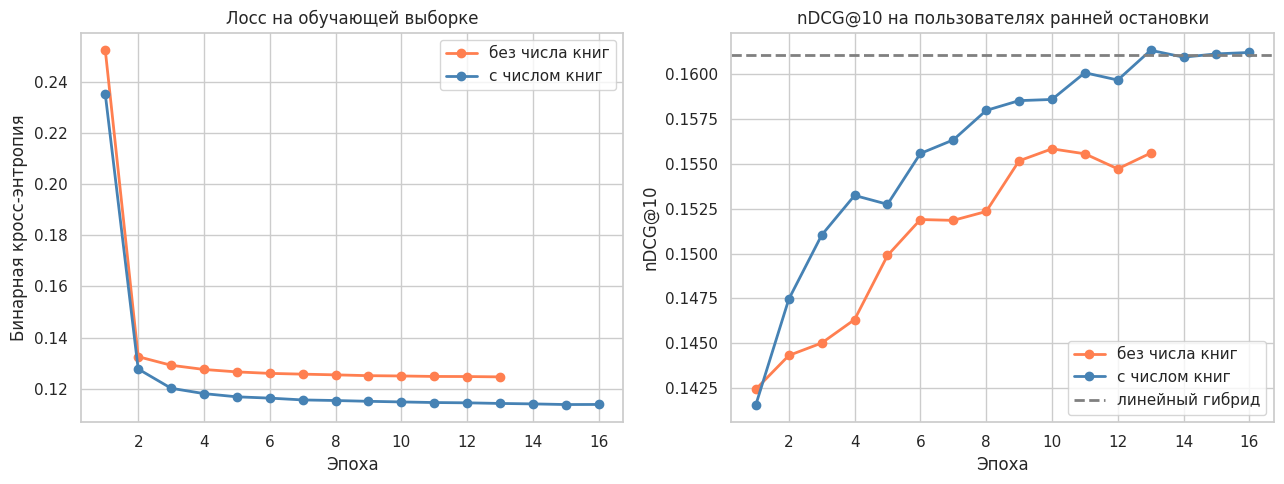

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for (name, h), color in zip(histories.items(), ('coral', 'steelblue')):
    axes[0].plot(h['эпоха'], h['loss'], color=color, lw=2, marker='o', label=name)
    axes[1].plot(h['эпоха'], h['nDCG@10 (ранняя остановка)'], color=color, lw=2, marker='o', label=name)
axes[1].axhline(hybrid.ranking_metrics(es_pool, es_linear, rel_val, K)['nDCG@10'], color='gray', lw=2, ls='--', label='линейный гибрид')
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('Бинарная кросс-энтропия')
axes[0].set_title('Лосс на обучающей выборке')
axes[1].set_xlabel('Эпоха')
axes[1].set_ylabel('nDCG@10')
axes[1].set_title('nDCG@10 на пользователях ранней остановки')
for ax in axes:
    ax.legend()
plt.tight_layout(); plt.show()

Сеть с числом книг остановилась после 16-й эпохи, лучшей была 13-я: nDCG@10 на пользователях ранней остановки 0,1614 против 0,1611 у линейного гибрида и 0,1577 у cf_implicit. Сеть без числа книг остановилась после 13-й эпохи с лучшим результатом 0,1558 на 10-й и до линейного гибрида не дотянулась. Лосс у сети с числом книг ниже на всех эпохах (0,1143 против 0,1247 на 13-й), то есть признак длины истории она использует. В первом прогоне с лимитом 10 эпох сеть с числом книг остановилась на 0,1586, и рост после 10-й эпохи подтвердил, что лимит обрывал обучение.

## 6. Проверка на тестовой выборке

Как в ноутбуке 02, модели-генераторы переобучаются на объединении обучающей и валидационной частей, новые пользователи моделируются среди пользователей теста, а веса линейного гибрида, λ и обученные сети переносятся с валидации без изменений. MMR применяется к скорам ранжировщика с тем же λ = 0,8, выбранным в ноутбуке 02.

In [9]:
del pool_val, es_pool

rel_test   = metrics.relevance_matrix(test, idx, THRESHOLD)
train_t, _ = pipeline.simulate_new_users(pd.concat([fit, val], ignore_index=True), rel_test, idx, n_users=N_NEW, seed=SEED)
fitted_t   = pipeline.fit_models(train_t, books, book_tags, idx)
test_users = np.flatnonzero(np.diff(rel_test.indptr))
pool_test  = pipeline.scored_pool(fitted_t, test_users, rel_test, n_per_model=N_PER_MODEL)
segment_t  = hybrid.segment_of(fitted_t.n_ratings)
seg_test   = {s: test_users[segment_t[test_users] == s] for s in SEGMENTS}

systems = {
    'cf_implicit':            hybrid.hybrid_score(pool_test, {'cf_implicit': 1.0}),
    'линейный гибрид':        hybrid.segment_score(pool_test, segment_t, {s: weights[('features', s)] for s in SEGMENTS}),
    'MLP без числа книг':     ranker.predict(models['без числа книг'], ranker.feature_matrix(pool_test, cols, fitted_t.n_ratings, False)),
    'MLP с числом книг':      ranker.predict(models['с числом книг'], ranker.feature_matrix(pool_test, cols, fitted_t.n_ratings, True)),
}
systems['MLP с числом книг + MMR'] = hybrid.mmr_rerank(pool_test, systems['MLP с числом книг'], fitted_t.genres, k=K, lam=LAMBDA)

final = []
for name, score in systems.items():
    row = {'система': name}
    for s, u in (('все', test_users), *((SEGMENTS[s], u) for s, u in seg_test.items())):
        row[f'nDCG@{K}, {s}'] = hybrid.ranking_metrics(pool_test, score, rel_test, K, users=u)[f'nDCG@{K}']
    m = hybrid.ranking_metrics(pool_test, score, rel_test, K)
    row.update({f'Precision@{K}': m[f'Precision@{K}'], f'Recall@{K}': m[f'Recall@{K}'],
                **hybrid.list_properties(pool_test, score, fitted_t.genres, gr_count, len(idx.books), K)})
    final.append(row)
final = pd.DataFrame(final)
final.round(4)

,система,"nDCG@10, все","nDCG@10, новые","nDCG@10, активные",Precision@10,Recall@10,ILS (жанры),жанров в списке,покрытие каталога,медиана популярности
0,cf_implicit,0.2017,0.0711,0.2159,0.0759,0.2418,0.5590,6.5351,0.9470,20177.0
1,линейный гибрид,0.2018,0.0737,0.2157,0.0777,0.2443,0.5525,6.6213,0.9417,20377.0
2,MLP без числа книг,0.1950,0.0715,0.2085,0.0767,0.2416,0.5724,6.4038,0.9611,19634.0
3,MLP с числом книг,0.2026,0.0717,0.2168,0.0792,0.2499,0.5778,6.3017,0.9532,17820.0
4,MLP с числом книг + MMR,0.2046,0.0716,0.2191,0.0802,0.2539,0.5263,6.9692,0.9558,17565.0


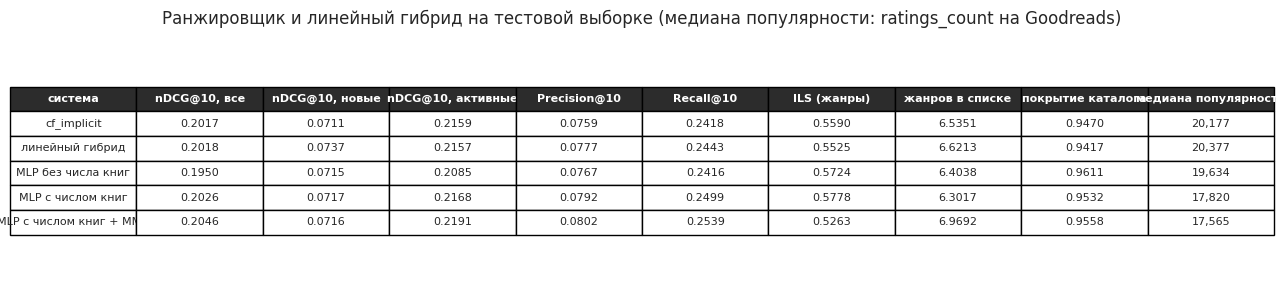

In [10]:
table = final.copy()
for col in table.columns[1:]:
    table[col] = table[col].map(lambda v: f'{v:,.0f}' if col == 'медиана популярности' else f'{v:.4f}')
show_table(table, 'Ранжировщик и линейный гибрид на тестовой выборке (медиана популярности: ratings_count на Goodreads)', fontsize=8); plt.show()

На тесте сеть с числом книг лучше cf_implicit и линейного гибрида по всем пользователям на небольшую величину: nDCG@10 0,2026 против 0,2017 и 0,2018. По Precision@10 и Recall@10 разрыв заметнее: 0,0792 и 0,2499 против 0,0759 и 0,2418 у cf_implicit. У новых пользователей лучшим остаётся линейный гибрид (0,0737 против 0,0717 у сети): популярность и контент с подобранными весами помогают им больше, чем сеть, в обучении которой новые пользователи составляли около 11% пользователей валидации. Сеть без числа книг хуже cf_implicit у активных пользователей.

MMR поверх сети повышает и разнообразие, и точность: nDCG@10 0,2046, Recall@10 0,2539, ILS 0,526 против 0,578 у сети без переранжирования. Это лучший результат по всем пользователям среди систем проекта. Вероятная причина в том, что сеть сильнее других собирает вверху списка похожие книги (у неё самый высокий ILS), например несколько книг одной серии, и часть этих мест тратится впустую, а MMR освобождает их для других жанров. Это предположение, отдельно оно не проверялось. Значимость разницы между системами тоже не проверялась: разница по всем пользователям в 0,001–0,003 nDCG может лежать в пределах случайного разброса.

Главный вопрос к ранжировщику: сможет ли он сохранить выигрыш линейного гибрида у пользователей с длинной историей и не потерять у пользователей с короткой. Таблица ниже повторяет разбивку по группам активности из ноутбука 02.

In [11]:
active   = seg_test['active']
groups   = pd.cut(fitted_t.n_ratings[active], bins=[3, 10, 30, 100, 1000], labels=['4–10', '11–30', '31–100', '>100'])
by_group = pd.DataFrame({name: [hybrid.ranking_metrics(pool_test, systems[name], rel_test, K, users=active[groups == g])[f'nDCG@{K}']
                                for g in groups.categories]
                         for name in ('cf_implicit', 'линейный гибрид', 'MLP без числа книг', 'MLP с числом книг')},
                        index=groups.categories)
by_group.insert(0, 'пользователей', pd.Series(groups).value_counts().reindex(groups.categories).values)
by_group.index.name = 'оценок в train'
by_group.round(4)

,пользователей,cf_implicit,линейный гибрид,MLP без числа книг,MLP с числом книг
оценок в train,,,,,
4–10,10747,0.2093,0.2034,0.1907,0.2025
11–30,10658,0.2127,0.2124,0.2078,0.2124
31–100,5592,0.2294,0.2389,0.2392,0.2450
>100,545,0.2709,0.2852,0.2564,0.2991


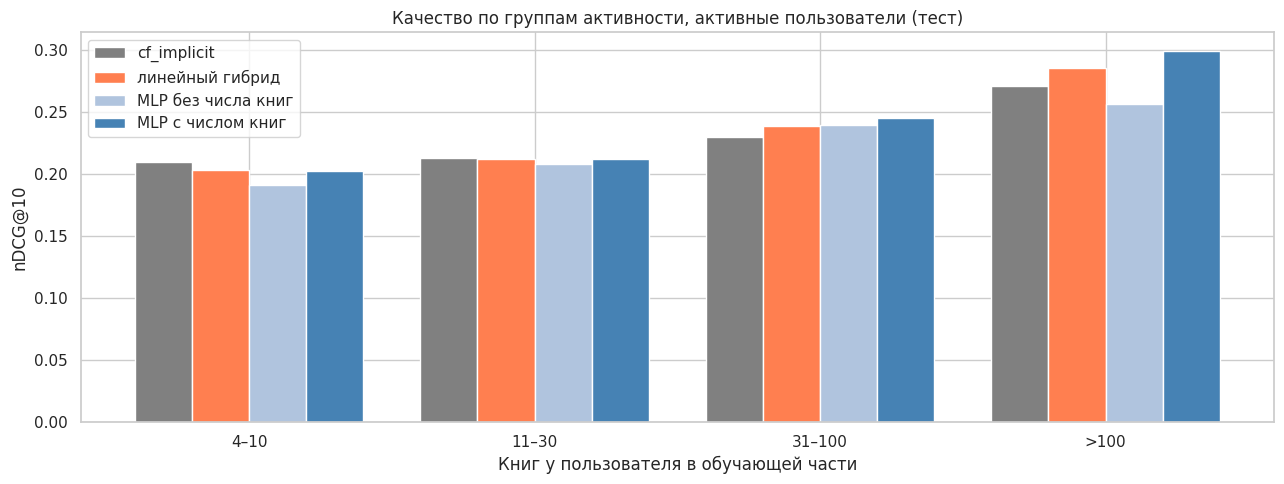

In [12]:
plot_df = by_group.drop(columns='пользователей')
x, width = np.arange(len(plot_df)), 0.2
colors   = ('gray', 'coral', 'lightsteelblue', 'steelblue')

fig, ax = plt.subplots(figsize=(13, 5))
for j, (name, color) in enumerate(zip(plot_df.columns, colors)):
    ax.bar(x + (j - 1.5) * width, plot_df[name], width=width, color=color, label=name)
ax.set_xticks(x)
ax.set_xticklabels(plot_df.index)
ax.set_xlabel('Книг у пользователя в обучающей части')
ax.set_ylabel(f'nDCG@{K}')
ax.set_title('Качество по группам активности, активные пользователи (тест)')
ax.legend()
plt.tight_layout(); plt.show()

Гибрид из ноутбука 02 проигрывал cf_implicit у пользователей с короткой историей и выигрывал у пользователей с длинной. Сеть с числом книг усилила выигрыш у тяжёлых читателей: при 31–100 и более чем 100 книгах она лучше всех систем, 0,2450 и 0,2991 против 0,2294 и 0,2709 у cf_implicit (+6,8% и +10,4%) и против 0,2389 и 0,2852 у линейного гибрида. Без числа книг у самой активной группы сеть падает до 0,2564, ниже cf_implicit. У пользователей с 4–10 книгами признак помогает (0,2025 против 0,1907 без него), но сеть всё ещё уступает cf_implicit (0,2093), так что проигрыш у лёгких читателей сохранился. В группе больше 100 книг всего 545 пользователей, и её результат менее надёжен, чем у остальных групп.

## 7. Выводы

Нейросетевой ранжировщик (MLP с двумя скрытыми слоями) ранжирует кандидатов общего пула по тем же колонкам, что и линейный гибрид, и по числу книг пользователя. На тесте вместе с MMR он даёт лучший результат проекта по всем пользователям: nDCG@10 0,2046 против 0,2017 у item-based CF на факте прочтения (+1,4%) и 0,2026 у линейного гибрида с MMR из ноутбука 02, Recall@10 0,2539 против 0,2418. Прирост держится на пользователях с длинной историей: при 31–100 и более чем 100 книгах сеть лучше cf_implicit на 6,8% и 10,4%.

Признак числа книг нужен: без него сеть хуже cf_implicit во всех группах активных пользователей. Это подтверждает вывод ноутбука 02: пользователям с короткой и длинной историей нужны разные правила комбинирования сигналов, и линейная сумма с одним набором весов этого не умеет, а нелинейная модель с признаком длины истории умеет частично.

Слабые места. У пользователей с 4–10 книгами сеть проигрывает cf_implicit 3,2%, у новых пользователей уступает линейному гибриду. Лосс поточечный: сеть учится отличать релевантного кандидата от нерелевантного и не учитывает позицию в списке, поэтому её преимущество по Precision и Recall больше, чем по nDCG. Списковый лосс (например, softmax по кандидатам пользователя) мог бы это исправить, но в этой работе не проверялся. Значимость разницы между системами не проверялась.

Сеть дешёвая в применении: около трёх тысяч умножений на кандидата, основное время инференса уходит на генерацию кандидатов. В сквозном пайплайне (run_pipeline.py) финальные рекомендации строит эта сеть с MMR.

Тестовая выборка в этом ноутбуке открывалась дважды: в первом прогоне с лимитом 10 эпох и в финальном с лимитом 30. Лимит подняли по кривой ранней остановки на валидации, результат финального прогона принят без дальнейших изменений.